In [1]:
import os,time
import numpy as np
import matplotlib.pyplot as plt

In [2]:
input_shape = (224, 224, 3)

num_classes = 2


In [3]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential, Model


In [4]:
inputs = layers.Input(shape=input_shape)


x = layers.Conv2D(32, (3,3), activation='relu')(inputs)
x = layers.MaxPooling2D((2,2))(x)
x = layers.Conv2D(64, (3,3), activation='relu')(x)
x = layers.MaxPooling2D((2,2))(x)
x = layers.Conv2D(128, (3,3), activation='relu')(x)
x = layers.MaxPooling2D((2,2))(x)
x = layers.Conv2D(256, (3,3), activation='relu')(x)
x = layers.MaxPooling2D((2,2))(x)

# global average polling layer

x= layers.GlobalAveragePooling2D()(x)

outputs = layers.Dense(num_classes, activation='softmax')(x)

model = Model(inputs, outputs=outputs)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Print the model summary
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,930 (1.48 MB)

 Trainable params: 388,930 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
from google.colab import drive
drive.mount('/content/drive')
data_path = output_path = "/content/drive/MyDrive/2animaldataset"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
train_npz = data_path + '/Dataset_image_train.npz'
train_data = np.load(train_npz)
train_images, train_targets = train_data["image_train"], train_data["labels_train"]
print("The traing data shape is :", train_images.shape, train_targets.shape)   #Targets are only names

#Loading validation data
val_npz = data_path + '/Dataset_image_val.npz'
val_data = np.load(val_npz)
val_images, val_targets = val_data["image_val"], val_data["labels_val"]
print("The validation data shape is :", val_images.shape, val_targets.shape)   #Targets are only names

The traing data shape is : (1080, 224, 224, 3) (1080, 2)
The validation data shape is : (20, 224, 224, 3) (20, 2)


In [8]:
#Model training
timestamp=time.time()
history1 = model.fit(x=train_images,y=train_targets, batch_size=128, epochs=10, validation_data =(val_images, val_targets), verbose=2)
#Save DNN model after training
model.save(output_path +'Image_CNN_8class.h5')
print('Training time: %s' % (timestamp - time.time())) #Get total training time

#Compute test accuracy
(loss, accuracy) = model.evaluate(x=val_images, y=val_targets, batch_size=5, verbose=2)
print("[INFO] loss={:.4f}, accuracy: {:.4f}%".format(loss,accuracy * 100))


Epoch 1/10
9/9 - 154s - 17s/step - accuracy: 0.5093 - loss: 13.6713 - val_accuracy: 0.5000 - val_loss: 1.3055
Epoch 2/10
9/9 - 145s - 16s/step - accuracy: 0.5426 - loss: 0.8379 - val_accuracy: 0.5500 - val_loss: 0.8097
Epoch 3/10
9/9 - 201s - 22s/step - accuracy: 0.5741 - loss: 0.6668 - val_accuracy: 0.7000 - val_loss: 0.8911
Epoch 4/10
9/9 - 201s - 22s/step - accuracy: 0.6389 - loss: 0.6294 - val_accuracy: 0.6500 - val_loss: 1.2977
Epoch 5/10
9/9 - 155s - 17s/step - accuracy: 0.6519 - loss: 0.6191 - val_accuracy: 0.6000 - val_loss: 1.0879
Epoch 6/10
9/9 - 191s - 21s/step - accuracy: 0.6556 - loss: 0.6184 - val_accuracy: 0.6500 - val_loss: 1.2621
Epoch 7/10
9/9 - 202s - 22s/step - accuracy: 0.6722 - loss: 0.6116 - val_accuracy: 0.6000 - val_loss: 0.9619
Epoch 8/10
9/9 - 163s - 18s/step - accuracy: 0.6602 - loss: 0.5996 - val_accuracy: 0.6500 - val_loss: 1.3659
Epoch 9/10
9/9 - 147s - 16s/step - accuracy: 0.6722 - loss: 0.5985 - val_accuracy: 0.6000 - val_loss: 1.3607
Epoch 10/10
9/9 - 

Training time: -1762.4103178977966
4/4 - 1s - 155ms/step - accuracy: 0.6000 - loss: 1.6909
[INFO] loss=1.6909, accuracy: 60.0000%


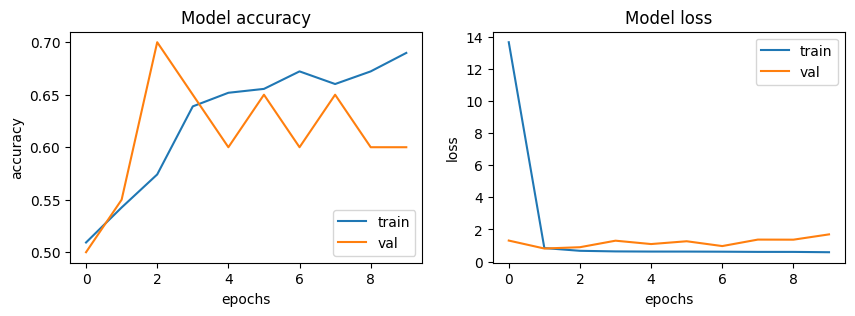

In [13]:
# Visualize Loss and Accuracy Rates
output = data_path + 'Output/'
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax = ax.ravel()
for i, met in enumerate(['accuracy', 'loss']):
    ax[i].plot(history1.history[met])
    ax[i].plot(history1.history['val_' + met])
    ax[i].set_title('Model {}'.format(met))
    ax[i].set_xlabel('epochs')
    ax[i].set_ylabel(met)
    ax[i].legend(['train', 'val'])

plt.savefig(output + 'Loss_Accuracy_CNN_Joint.png')
plt.show()

In [14]:
'''
# Load pre-trained weight and make some predictions
model.load_weights(output +'Image_CNN_8class.h5', by_name = True)
print("The pre-trained weight loaded.")
'''
#Compute test accuracy
(loss, accuracy) = model.evaluate(x=val_images, y=val_targets, batch_size=5, verbose=2)
print("[INFO] loss={:.4f}, accuracy: {:.4f}%".format(loss,accuracy * 100))

4/4 - 1s - 156ms/step - accuracy: 0.6000 - loss: 1.6909
[INFO] loss=1.6909, accuracy: 60.0000%



--- Confusion matrix for test data ---



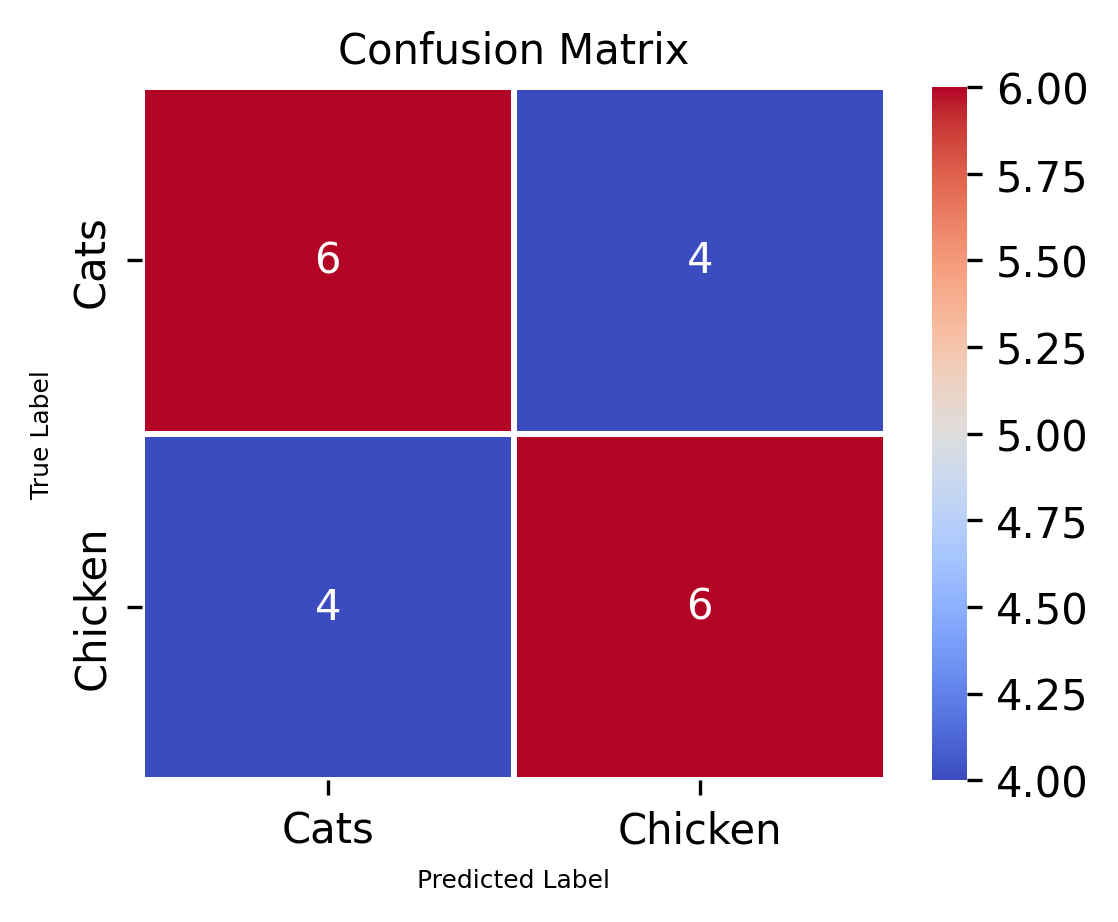

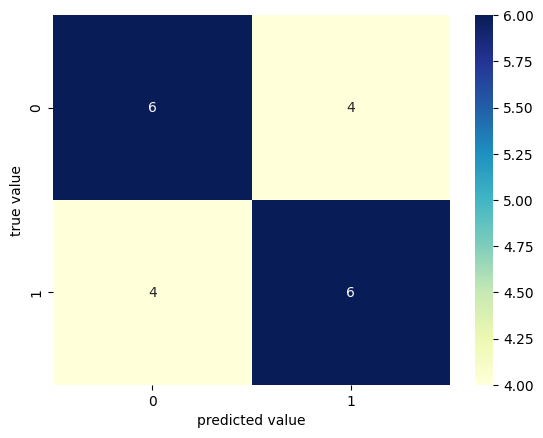

In [16]:
# Get classwise confusion matrix
from sklearn import metrics
import seaborn as sns

# Define the classes name
image_calss = ["Cats","Chicken"]

def show_confusion_matrix(validations, predictions):
    matrix = metrics.confusion_matrix(validations, predictions)
    #plt.figure(figsize=(6, 4), dpi = 300)    #ORG
    plt.figure(figsize=(4, 3), dpi = 300)
    sns.heatmap(matrix,
                cmap="coolwarm",
                linecolor='white',
                linewidths=1,
                xticklabels=image_calss,
                yticklabels=image_calss,
                annot=True,
                fmt="d")
    plt.title("Confusion Matrix", fontsize=10)
    plt.ylabel("True Label", fontsize=6)
    plt.xlabel("Predicted Label", fontsize=6)
    plt.savefig(output + 'Confusion_matrix.png')
    plt.savefig(output + 'Confusion_matrix.pdf')
    plt.show()

print("\n--- Confusion matrix for test data ---\n")
predictions = model.predict(x=val_images,verbose=0) #Network predictions

# Take the class with the highest probability from the test predictions
max_y_pred_test = np.argmax(predictions, axis=1)
max_y_test = np.argmax(val_targets, axis=1)

show_confusion_matrix(max_y_test, max_y_pred_test)

# OR Simply you can print a confusion matrix as:
conf_matrix = metrics.confusion_matrix(max_y_test, max_y_pred_test)
sns.heatmap(conf_matrix,cmap="YlGnBu",annot=True,fmt='g');
plt.xlabel('predicted value')
plt.ylabel('true value')
plt.show()
